29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (10000, 28, 28, 1)
Testing data: (1000, 28, 28, 1)

Training VAE
Epoch 1/5 | Reconstruction: 366.8143 | KL Loss: 8.1155 | Total Loss: 374.9298
Epoch 2/5 | Reconstruction: 291.0659 | KL Loss: 6.7556 | Total Loss: 297.8215
Epoch 3/5 | Reconstruction: 279.8624 | KL Loss: 6.4756 | Total Loss: 286.3380
Epoch 4/5 | Reconstruction: 275.3463 | KL Loss: 6.2757 | Total Loss: 281.6220
Epoch 5/5 | Reconstruction: 271.9409 | KL Loss: 6.1406 | Total Loss: 278.0815
VAE training time: 12.96 seconds


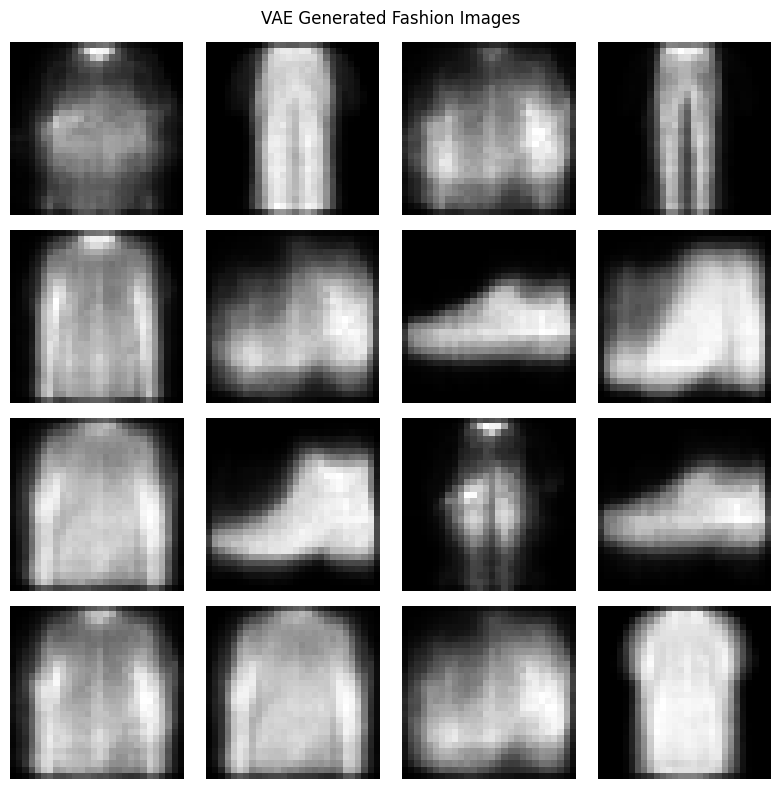

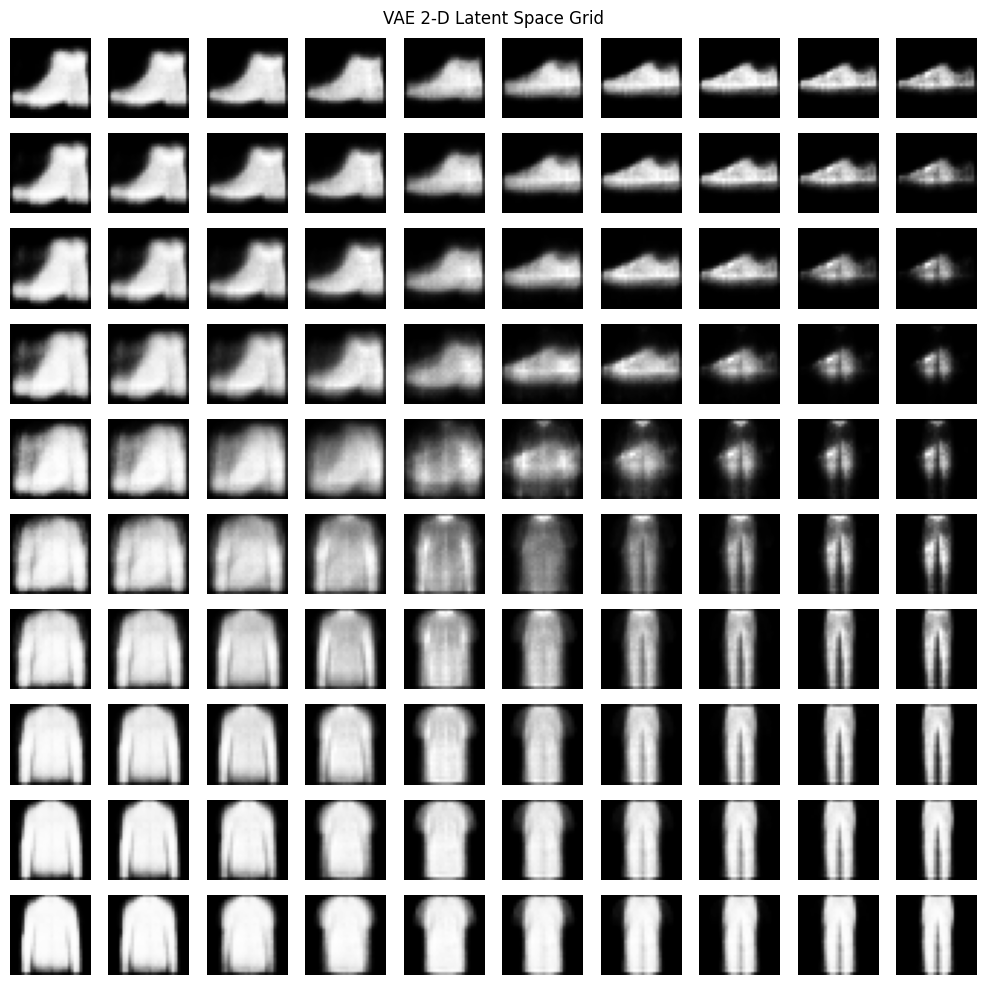

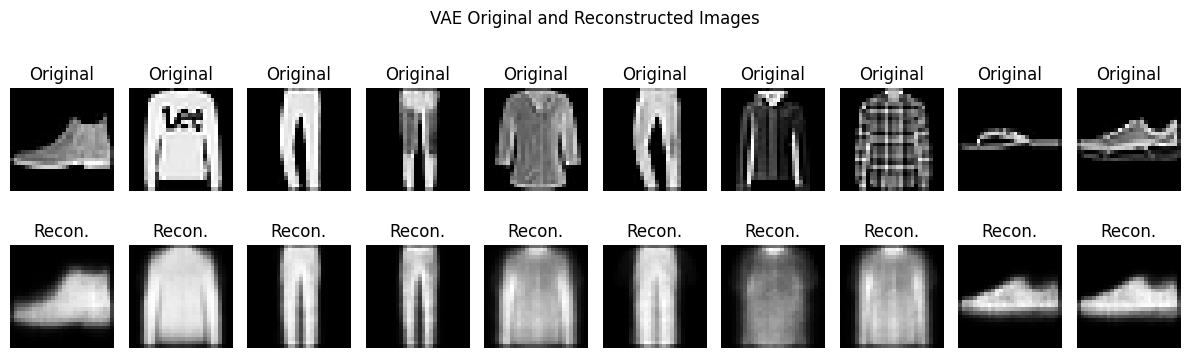


Generator


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_113 (Dense)               │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 14, 14, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 766,401 (2.92 MB)

 Trainable params: 766,017 (2.92 MB)

 Non-trainable params: 384 (1.50 KB)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_44 (Conv2D)              │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_45 (Conv2D)              │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_18 (Flatten)            │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_114 (Dense)               │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# EXPERIMENT 29: VAE AND GAN SAMPLE GENERATION

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras import layers, models

np.random.seed(42)
tf.random.set_seed(42)

# --------------------------------------------------
# 1. LOAD FASHION-MNIST DATA
# --------------------------------------------------

(X_train, _), (X_test, _) = fashion_mnist.load_data()

X_train = X_train[:10000].astype("float32") / 255.0
X_test = X_test[:1000].astype("float32") / 255.0

X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# --------------------------------------------------
# 2. BUILD VARIATIONAL AUTOENCODER (VAE)
# --------------------------------------------------

latent_dim = 2

# Encoder
encoder_input = layers.Input(shape=(28, 28, 1))

x = layers.Flatten()(encoder_input)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dense(128, activation="relu")(x)

z_mean = layers.Dense(latent_dim)(x)
z_log_var = layers.Dense(latent_dim)(x)

# Reparameterization
def sampling(args):
    mean, log_var = args

    epsilon = tf.random.normal(shape=tf.shape(mean))

    return mean + tf.exp(0.5 * log_var) * epsilon

z = layers.Lambda(sampling)([z_mean, z_log_var])

encoder = models.Model(
    encoder_input,
    [z_mean, z_log_var, z],
    name="encoder"
)

# Decoder
decoder_input = layers.Input(shape=(latent_dim,))

x = layers.Dense(128, activation="relu")(decoder_input)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dense(784, activation="sigmoid")(x)

decoder_output = layers.Reshape((28, 28, 1))(x)

decoder = models.Model(
    decoder_input,
    decoder_output,
    name="decoder"
)

# --------------------------------------------------
# 3. TRAIN VAE
# --------------------------------------------------

optimizer = tf.keras.optimizers.Adam(0.001)

vae_epochs = 5
batch_size = 128

vae_reconstruction_losses = []
vae_kl_losses = []
vae_total_losses = []

train_dataset = tf.data.Dataset.from_tensor_slices(X_train)
train_dataset = train_dataset.shuffle(10000).batch(batch_size)

@tf.function
def train_vae_step(images):

    with tf.GradientTape() as tape:

        mean, log_var, z = encoder(images, training=True)

        reconstructed = decoder(z, training=True)

        # Reconstruction loss
        reconstruction_loss = tf.reduce_mean(
            tf.reduce_sum(
                tf.keras.losses.binary_crossentropy(
                    images, reconstructed
                ),
                axis=(1, 2)
            )
        )

        # KL divergence
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(
                1 + log_var - tf.square(mean) - tf.exp(log_var),
                axis=1
            )
        )

        total_loss = reconstruction_loss + kl_loss

    variables = encoder.trainable_variables + decoder.trainable_variables

    gradients = tape.gradient(total_loss, variables)

    optimizer.apply_gradients(zip(gradients, variables))

    return reconstruction_loss, kl_loss, total_loss


print("\nTraining VAE")

vae_start = time.time()

for epoch in range(vae_epochs):

    rec_total = 0
    kl_total = 0
    total_total = 0
    batches = 0

    for batch in train_dataset:

        rec, kl, total = train_vae_step(batch)

        rec_total += float(rec)
        kl_total += float(kl)
        total_total += float(total)

        batches += 1

    rec_avg = rec_total / batches
    kl_avg = kl_total / batches
    total_avg = total_total / batches

    vae_reconstruction_losses.append(rec_avg)
    vae_kl_losses.append(kl_avg)
    vae_total_losses.append(total_avg)

    print(
        f"Epoch {epoch + 1}/{vae_epochs} | "
        f"Reconstruction: {rec_avg:.4f} | "
        f"KL Loss: {kl_avg:.4f} | "
        f"Total Loss: {total_avg:.4f}"
    )

vae_time = time.time() - vae_start

print("VAE training time:", round(vae_time, 2), "seconds")

# --------------------------------------------------
# 4. GENERATE VAE IMAGES
# --------------------------------------------------

random_latent = np.random.normal(
    size=(16, latent_dim)
).astype("float32")

generated_vae = decoder.predict(
    random_latent,
    verbose=0
)

plt.figure(figsize=(8, 8))

for i in range(16):

    plt.subplot(4, 4, i + 1)
    plt.imshow(generated_vae[i, :, :, 0], cmap="gray")
    plt.axis("off")

plt.suptitle("VAE Generated Fashion Images")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 5. PLOT 2-D LATENT SPACE GRID
# --------------------------------------------------

grid_size = 10

grid_x = np.linspace(-3, 3, grid_size)
grid_y = np.linspace(-3, 3, grid_size)

plt.figure(figsize=(10, 10))

for i, yi in enumerate(grid_y):

    for j, xi in enumerate(grid_x):

        latent_sample = np.array([[xi, yi]], dtype="float32")

        image = decoder.predict(
            latent_sample,
            verbose=0
        )[0, :, :, 0]

        plt.subplot(grid_size, grid_size,
                    i * grid_size + j + 1)

        plt.imshow(image, cmap="gray")
        plt.axis("off")

plt.suptitle("VAE 2-D Latent Space Grid")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. VAE RECONSTRUCTION
# --------------------------------------------------

mean, log_var, z = encoder.predict(
    X_test[:10],
    verbose=0
)

reconstructed_vae = decoder.predict(
    z,
    verbose=0
)

plt.figure(figsize=(12, 4))

for i in range(10):

    plt.subplot(2, 10, i + 1)
    plt.imshow(X_test[i, :, :, 0], cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_vae[i, :, :, 0], cmap="gray")
    plt.title("Recon.")
    plt.axis("off")

plt.suptitle("VAE Original and Reconstructed Images")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. BUILD DCGAN GENERATOR
# --------------------------------------------------

noise_dim = 100

generator = models.Sequential([
    layers.Input(shape=(noise_dim,)),

    layers.Dense(7 * 7 * 128),
    layers.Reshape((7, 7, 128)),

    layers.BatchNormalization(),
    layers.ReLU(),

    layers.Conv2DTranspose(
        64, 4, strides=2, padding="same"
    ),

    layers.BatchNormalization(),
    layers.ReLU(),

    layers.Conv2DTranspose(
        1, 4, strides=2, padding="same",
        activation="sigmoid"
    )
], name="generator")

# --------------------------------------------------
# 8. BUILD DCGAN DISCRIMINATOR
# --------------------------------------------------

discriminator = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        64, 4, strides=2, padding="same"
    ),

    layers.LeakyReLU(0.2),

    layers.Conv2D(
        128, 4, strides=2, padding="same"
    ),

    layers.LeakyReLU(0.2),

    layers.Flatten(),

    layers.Dense(1)
], name="discriminator")

print("\nGenerator")
generator.summary()

print("\nDiscriminator")
discriminator.summary()

# --------------------------------------------------
# 9. DCGAN TRAINING FUNCTIONS
# --------------------------------------------------

g_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)
d_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)

cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

@tf.function
def gan_train_step(real_images):

    noise = tf.random.normal(
        [tf.shape(real_images)[0], noise_dim]
    )

    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(
            real_images, training=True
        )

        fake_output = discriminator(
            fake_images, training=True
        )

        # Generator loss
        g_loss = cross_entropy(
            tf.ones_like(fake_output),
            fake_output
        )

        # Discriminator loss
        real_loss = cross_entropy(
            tf.ones_like(real_output),
            real_output
        )

        fake_loss = cross_entropy(
            tf.zeros_like(fake_output),
            fake_output
        )

        d_loss = real_loss + fake_loss

    g_gradients = g_tape.gradient(
        g_loss, generator.trainable_variables
    )

    d_gradients = d_tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    d_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    return g_loss, d_loss

# --------------------------------------------------
# 10. TRAIN DCGAN
# --------------------------------------------------

gan_epochs = 5
gan_batch_size = 128

gan_dataset = tf.data.Dataset.from_tensor_slices(X_train)
gan_dataset = gan_dataset.shuffle(10000).batch(gan_batch_size)

generator_losses = []
discriminator_losses = []

print("\nTraining DCGAN")

gan_start = time.time()

for epoch in range(gan_epochs):

    g_total = 0
    d_total = 0
    batches = 0

    for batch in gan_dataset:

        g_loss, d_loss = gan_train_step(batch)

        g_total += float(g_loss)
        d_total += float(d_loss)

        batches += 1

    g_avg = g_total / batches
    d_avg = d_total / batches

    generator_losses.append(g_avg)
    discriminator_losses.append(d_avg)

    print(
        f"Epoch {epoch + 1}/{gan_epochs} | "
        f"Generator Loss: {g_avg:.4f} | "
        f"Discriminator Loss: {d_avg:.4f}"
    )

    # Save/display generated images every epoch
    noise = tf.random.normal([16, noise_dim])

    generated_images = generator(
        noise, training=False
    ).numpy()

    plt.figure(figsize=(6, 6))

    for i in range(16):

        plt.subplot(4, 4, i + 1)
        plt.imshow(generated_images[i, :, :, 0], cmap="gray")
        plt.axis("off")

    plt.suptitle(f"DCGAN Generated Images - Epoch {epoch + 1}")
    plt.tight_layout()
    plt.show()

gan_time = time.time() - gan_start

print("GAN training time:", round(gan_time, 2), "seconds")

# --------------------------------------------------
# 11. GENERATE FINAL GAN SAMPLES
# --------------------------------------------------

noise = tf.random.normal([25, noise_dim])

final_gan_images = generator(
    noise, training=False
).numpy()

plt.figure(figsize=(8, 8))

for i in range(25):

    plt.subplot(5, 5, i + 1)

    plt.imshow(
        final_gan_images[i, :, :, 0],
        cmap="gray"
    )

    plt.axis("off")

plt.suptitle("Final DCGAN Generated Fashion Images")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 12. PLOT GENERATOR LOSS
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.plot(
    generator_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Generator Loss")
plt.title("DCGAN Generator Loss")
plt.grid(True)
plt.show()

# --------------------------------------------------
# 13. PLOT DISCRIMINATOR LOSS
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.plot(
    discriminator_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Discriminator Loss")
plt.title("DCGAN Discriminator Loss")
plt.grid(True)
plt.show()

# --------------------------------------------------
# 14. COMPARE VAE AND GAN TRAINING TIME
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    ["VAE", "DCGAN"],
    [vae_time, gan_time]
)

plt.ylabel("Training Time (seconds)")
plt.title("VAE vs DCGAN Training Time")

plt.show()

# --------------------------------------------------
# 15. FINAL RESULTS
# --------------------------------------------------

print("\nFINAL RESULTS")
print("=" * 50)

print("VAE Training Time:", round(vae_time, 2), "seconds")
print("DCGAN Training Time:", round(gan_time, 2), "seconds")

print("Final VAE Loss:", round(vae_total_losses[-1], 4))
print("Final Generator Loss:", round(generator_losses[-1], 4))
print("Final Discriminator Loss:",
      round(discriminator_losses[-1], 4))

print("=" * 50)

print("\nExperiment 29 completed successfully!")